In [2]:
import pandas as pd
import numpy as np
import re
import requests
from bs4 import BeautifulSoup
import time



In [3]:
API_KEY = "CG-ZcTSmjFqi7Yg9XdsXYBLZPiX"

url = "https://api.coingecko.com/api/v3/coins/markets"

headers = {
    "x-cg-demo-api-key": API_KEY
}

all_crypto = []

for page in range(1, 3):

    params = {
        "vs_currency": "usd",
        "order": "market_cap_desc",
        "per_page": 250,
        "page": page,
        "sparkline": "false"
    }

    response = requests.get(
        url,
        params=params,
        headers=headers,
        timeout=30
    )

    print(f"Page {page}: {response.status_code}")

    if response.status_code == 200:
        data = response.json()
        all_crypto.extend(data)
        print("Coins collected:", len(data))

    else:
        print("Error:", response.text)
        break

    time.sleep(2)

crypto_df = pd.DataFrame(all_crypto)

print("Total coins:", len(crypto_df))
print("Shape:", crypto_df.shape)

Page 1: 200
Coins collected: 250
Page 2: 200
Coins collected: 250
Total coins: 500
Shape: (500, 26)


In [4]:

# page 3 
test_params = {
    "vs_currency": "usd",
    "order": "market_cap_desc",
    "per_page": 100,
    "page": 3,
    "sparkline": "false"
}

test_response = requests.get(
    url,
    params=test_params,
    headers=headers,
    timeout=30
)
print(test_response.status_code)
print(test_response.text)

200
[{"id":"axie-infinity","symbol":"axs","name":"Axie Infinity","image":"https://coin-images.coingecko.com/coins/images/13029/large/axie_infinity_logo.png?1696512817","current_price":0.921504,"market_cap":161924693,"market_cap_rank":201,"fully_diluted_valuation":248976451,"total_volume":23721148,"high_24h":0.976326,"low_24h":0.912835,"price_change_24h":-0.04531898383434607,"price_change_percentage_24h":-4.69048,"market_cap_change_24h":-7847065.417578518,"market_cap_change_percentage_24h":-4.62213,"circulating_supply":175597599.66801068,"total_supply":270000000.0,"max_supply":270000000.0,"ath":164.9,"ath_change_percentage":-99.44117,"ath_date":"2021-11-06T11:29:29.000Z","atl":0.123718,"atl_change_percentage":644.84144,"atl_date":"2020-11-06T00:05:43.000Z","roi":null,"last_updated":"2026-10-29T03:25:53.000Z"},{"id":"chain-2","symbol":"xcn","name":"Onyxcoin","image":"https://coin-images.coingecko.com/coins/images/24210/large/onyxlogo.jpg?1696523397","current_price":0.00401876,"market_cap

In [5]:
print(crypto_df.shape)

(500, 26)


In [6]:
crypto_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 26 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   id                                500 non-null    str    
 1   symbol                            500 non-null    str    
 2   name                              500 non-null    str    
 3   image                             500 non-null    str    
 4   current_price                     500 non-null    float64
 5   market_cap                        500 non-null    int64  
 6   market_cap_rank                   500 non-null    int64  
 7   fully_diluted_valuation           500 non-null    float64
 8   total_volume                      500 non-null    float64
 9   high_24h                          500 non-null    float64
 10  low_24h                           500 non-null    float64
 11  price_change_24h                  482 non-null    float64
 12  price_change_percen

In [7]:
# describe
crypto_df.describe()

,current_price,market_cap,market_cap_rank,fully_diluted_valuation,total_volume,high_24h,low_24h,price_change_24h,price_change_percentage_24h,market_cap_change_24h,market_cap_change_percentage_24h,circulating_supply,total_supply,max_supply,ath,ath_change_percentage,atl,atl_change_percentage
count,5.000000e+02,5.000000e+02,500.000000,5.000000e+02,5.000000e+02,500.000000,500.000000,4.820000e+02,482.000000,4.820000e+02,482.000000,5.000000e+02,5.000000e+02,2.840000e+02,5.000000e+02,500.000000,5.000000e+02,5.000000e+02
mean,4.199397e+02,5.514132e+09,250.500000,6.062640e+09,2.362684e+08,421.198839,410.928658,-5.571635e+00,-1.941380,-8.595535e+07,-1.828618,3.774598e+14,8.494085e+14,1.493930e+15,3.798279e+05,-23.885743,1.689847e+02,4.251393e+04
std,5.086406e+03,7.353763e+10,144.481833,7.376114e+10,2.499976e+09,5199.680367,5074.050613,6.876945e+01,4.112487,1.064302e+09,4.374875,8.234360e+15,1.878273e+16,2.492175e+16,8.474664e+06,843.947302,2.658952e+03,4.541225e+05
min,3.429420e-10,4.504766e+07,1.000000,1.968900e-02,0.000000e+00,0.000000,0.000000,-1.099249e+03,-24.294160,-2.224820e+10,-24.190570,1.184000e+03,1.184000e+03,3.666600e+04,6.498000e-09,-100.000000,5.636600e-11,0.000000e+00
25%,6.442625e-02,6.407815e+07,125.750000,8.268570e+07,5.155552e+05,0.052593,0.048079,-1.740868e-02,-3.934953,-7.465280e+06,-3.907115,9.379953e+07,1.000000e+08,4.842288e+08,4.641767e-01,-95.231953,1.126358e-02,2.807972e+01
50%,4.152615e-01,1.158342e+08,250.500000,1.870913e+08,4.240604e+06,0.367910,0.350850,-1.097461e-03,-1.821015,-1.829309e+06,-1.788640,5.585683e+08,1.000000e+09,1.000000e+09,1.260000e+00,-76.141180,1.115775e-01,9.901643e+01
75%,1.152500e+00,3.577313e+08,375.250000,6.430214e+08,1.767836e+07,1.140000,1.132500,1.110000e-16,0.000000,5.230755e+03,0.007143,3.005680e+09,8.235687e+09,1.000000e+10,1.138000e+01,-24.759818,9.541527e-01,7.797648e+02
max,7.996900e+04,1.604131e+12,500.000000,1.604138e+12,4.630429e+10,81751.000000,79819.000000,2.171000e+01,29.718720,2.194265e+08,29.714980,1.841261e+17,4.200000e+17,4.200000e+17,1.895000e+08,18791.643890,5.829600e+04,8.595394e+06


In [8]:
# duplicates
 
crypto_check = crypto_df.copy()

for col in crypto_check.columns:
    crypto_check[col] = crypto_check[col].apply(
        lambda x: str(x) if isinstance(x, (dict, list)) else x
    )

print("Duplicate rows:", crypto_check.duplicated().sum())


Duplicate rows: 0


In [9]:
# isnall
crypto_df.isnull().sum()

id                                    0
symbol                                0
name                                  0
image                                 0
current_price                         0
market_cap                            0
market_cap_rank                       0
fully_diluted_valuation               0
total_volume                          0
high_24h                              0
low_24h                               0
price_change_24h                     18
price_change_percentage_24h          18
market_cap_change_24h                18
market_cap_change_percentage_24h     18
circulating_supply                    0
total_supply                          0
max_supply                          216
ath                                   0
ath_change_percentage                 0
ath_date                              0
atl                                   0
atl_change_percentage                 0
atl_date                              0
roi                                 463


In [10]:
# missing percentage
(crypto_df.isnull().sum()/len(crypto_df))*100

id                                   0.0
symbol                               0.0
name                                 0.0
image                                0.0
current_price                        0.0
market_cap                           0.0
market_cap_rank                      0.0
fully_diluted_valuation              0.0
total_volume                         0.0
high_24h                             0.0
low_24h                              0.0
price_change_24h                     3.6
price_change_percentage_24h          3.6
market_cap_change_24h                3.6
market_cap_change_percentage_24h     3.6
circulating_supply                   0.0
total_supply                         0.0
max_supply                          43.2
ath                                  0.0
ath_change_percentage                0.0
ath_date                             0.0
atl                                  0.0
atl_change_percentage                0.0
atl_date                             0.0
roi             

In [11]:
# missing values
crypto_df.isnull().sum().sum()

np.int64(751)

In [12]:
#rows and columns
crypto_df.shape

(500, 26)

In [13]:
url = "https://books.toscrape.com//"

In [14]:
# send the request
response = requests.get(url, headers=headers)

# check if the request was successful
response.status_code

200

In [15]:
# scrape the first page

soup = BeautifulSoup(response.content,"html.parser")
print(soup)


<!DOCTYPE html>

<!--[if lt IE 7]>      <html lang="en-us" class="no-js lt-ie9 lt-ie8 lt-ie7"> <![endif]-->
<!--[if IE 7]>         <html lang="en-us" class="no-js lt-ie9 lt-ie8"> <![endif]-->
<!--[if IE 8]>         <html lang="en-us" class="no-js lt-ie9"> <![endif]-->
<!--[if gt IE 8]><!--> <html class="no-js" lang="en-us"> <!--<![endif]-->
<head>
<title>
    All products | Books to Scrape - Sandbox
</title>
<meta content="text/html; charset=utf-8" http-equiv="content-type"/>
<meta content="24th Jun 2016 09:29" name="created"/>
<meta content="" name="description"/>
<meta content="width=device-width" name="viewport"/>
<meta content="NOARCHIVE,NOCACHE" name="robots"/>
<!-- Le HTML5 shim, for IE6-8 support of HTML elements -->
<!--[if lt IE 9]>
        <script src="//html5shim.googlecode.com/svn/trunk/html5.js"></script>
        <![endif]-->
<link href="static/oscar/favicon.ico" rel="shortcut icon"/>
<link href="static/oscar/css/styles.css" rel="stylesheet" type="text/css"/>
<link href="s

In [16]:
# make a empty data set

data =[]

In [17]:


for book in soup.select("article.product_pod"):

        title = book.h3.a["title"]

        price = book.find(
            "p", class_="price_color"
        ).text.strip()

        rating = book.find(
            "p", class_="star-rating"
        )["class"][1]

        availability = book.find(
            "p", class_="instock availability"
        ).text.strip()

        book_url = book.h3.a["href"]

        data.append({
            "title": title,
            "price": price,
            "rating": rating,
            "availability": availability,
            "book_url": book_url
        })

print("Number of books:", len(data))

Number of books: 20


In [18]:
# display the books from the data

data_df = pd.DataFrame(data)

data_df.head()

,title,price,rating,availability,book_url
0,A Light in the Attic,£51.77,Three,In stock,catalogue/a-light-in-the-attic_1000/index.html
1,Tipping the Velvet,£53.74,One,In stock,catalogue/tipping-the-velvet_999/index.html
2,Soumission,£50.10,One,In stock,catalogue/soumission_998/index.html
3,Sharp Objects,£47.82,Four,In stock,catalogue/sharp-objects_997/index.html
4,Sapiens: A Brief History of Humankind,£54.23,Five,In stock,catalogue/sapiens-a-brief-history-of-humankind...


In [19]:
# save the book  raw data
data_df.to_csv("data .csv",index = False)
print(data_df)

                                                title   price rating  \
0                                A Light in the Attic  £51.77  Three   
1                                  Tipping the Velvet  £53.74    One   
2                                          Soumission  £50.10    One   
3                                       Sharp Objects  £47.82   Four   
4               Sapiens: A Brief History of Humankind  £54.23   Five   
5                                     The Requiem Red  £22.65    One   
6   The Dirty Little Secrets of Getting Your Dream...  £33.34   Four   
7   The Coming Woman: A Novel Based on the Life of...  £17.93  Three   
8   The Boys in the Boat: Nine Americans and Their...  £22.60   Four   
9                                     The Black Maria  £52.15    One   
10     Starving Hearts (Triangular Trade Trilogy, #1)  £13.99    Two   
11                              Shakespeare's Sonnets  £20.66   Four   
12                                        Set Me Free  £17.46   

# Book Data Cleaning

In [20]:
print("Dataset shape:",data_df.shape)

print("\nData types:")
print(data_df.dtypes)

print("\n missing values")
print(data_df.isnull().sum())

print("\n duplicate rows:")

Dataset shape: (20, 5)

Data types:
title           str
price           str
rating          str
availability    str
book_url        str
dtype: object

 missing values
title           0
price           0
rating          0
availability    0
book_url        0
dtype: int64

 duplicate rows:


In [21]:
# Remove leading/trailing spaces
data_df["title"] = data_df["title"].str.strip()

# Replace multiple spaces with a single space
data_df["title"] = data_df["title"].str.replace(
    r"\s+", " ", regex=True
)

# Clean availability text
data_df["availability"] = data_df["availability"].str.strip()
data_df["availability"] = data_df["availability"].str.replace(
    r"\s+", " ", regex=True
)

In [22]:
# Remove £ symbol
data_df["price"] = data_df["price"].str.replace(
    "£", "", regex=False
)

# Remove extra spaces
data_df["price"] = data_df["price"].str.strip()

# Convert to numeric
data_df["price"] = pd.to_numeric(
    data_df["price"],
    errors="coerce"
)

print(data_df["price"].head())
print("\nPrice data type:", data_df["price"].dtype)

0    51.77
1    53.74
2    50.10
3    47.82
4    54.23
Name: price, dtype: float64

Price data type: float64


In [23]:
rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

data_df["rating"] = data_df["rating"].map(rating_map)

print(data_df["rating"].value_counts().sort_index())

rating
1    6
2    3
3    3
4    4
5    4
Name: count, dtype: int64


In [24]:
data_df["stock_count"] = data_df["availability"].str.extract(
    r"\((\d+) available\)"
)

data_df["stock_count"] = pd.to_numeric(
    data_df["stock_count"],
    errors="coerce"
)

display(
    data_df[["availability", "stock_count"]].head()
)

,availability,stock_count
0,In stock,NaN
1,In stock,NaN
2,In stock,NaN
3,In stock,NaN
4,In stock,NaN


In [25]:
print("Missing values before cleaning:")
print(data_df.isnull().sum())

Missing values before cleaning:
title            0
price            0
rating           0
availability     0
book_url         0
stock_count     20
dtype: int64


In [26]:
data_df = data_df.dropna(
    subset=[
        "title",
        "price",
        "rating",
        "stock_count"
    ]
)

print("Shape after removing incomplete records:", data_df.shape)

Shape after removing incomplete records: (0, 6)


In [27]:
# Remove invalid values
data_df = data_df[
    (data_df["price"] > 0) &
    (data_df["rating"].between(1, 5)) &
    (data_df["stock_count"] >= 0)
]

print("Shape after validation:", data_df.shape)

Shape after validation: (0, 6)


In [28]:
print(
    "Duplicate titles before:",
    data_df["title"].duplicated().sum()
)

data_df = data_df.drop_duplicates(
    subset=["title"],
    keep="first"
)

print(
    "Duplicate titles after:",
    data_df["title"].duplicated().sum()
)

Duplicate titles before: 0
Duplicate titles after: 0


In [29]:
data_df["title"] = data_df["title"].astype(str)
data_df["price"] = data_df["price"].astype(float)
data_df["rating"] = data_df["rating"].astype(int)
data_df["stock_count"] = data_df["stock_count"].astype(int)
print(data_df.dtypes)

title               str
price           float64
rating            int64
availability        str
book_url            str
stock_count       int64
dtype: object


In [30]:
data_df["price_range"] = pd.cut(
    data_df["price"],
    bins=[0, 20, 40, 60],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

print(data_df["price_range"].value_counts())

price_range
Low       0
Medium    0
High      0
Name: count, dtype: int64


In [31]:
data_df["stock_status"] = data_df["stock_count"].apply(
    lambda x:
        "Low Stock" if x < 10
        else "Medium Stock" if x < 30
        else "High Stock"
)

print(data_df["stock_status"].value_counts())

Series([], Name: count, dtype: int64)


In [32]:
print("Final dataset shape:", data_df.shape)

print("\nMissing values:")
print(data_df.isnull().sum())

print("\nDuplicate titles:")
print(data_df["title"].duplicated().sum())

print("\nData types:")
print(data_df.dtypes)

display(data_df.head(10))

Final dataset shape: (0, 8)

Missing values:
title           0
price           0
rating          0
availability    0
book_url        0
stock_count     0
price_range     0
stock_status    0
dtype: int64

Duplicate titles:
0

Data types:
title                str
price            float64
rating             int64
availability         str
book_url             str
stock_count        int64
price_range     category
stock_status       int64
dtype: object


,title,price,rating,availability,book_url,stock_count,price_range,stock_status


In [33]:
data_df.to_csv(
    "cleaned_books_data.csv",
    index=False
)

print("Cleaned book dataset saved successfully!")

Cleaned book dataset saved successfully!


# Crypto Currency Data Cleaning

In [34]:
# Clean column names

crypto_df.columns = (
    crypto_df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ","_")
)

In [35]:
# remove the duplicates
crypto_df = crypto_df.drop_duplicates(subset="id", keep="first")


In [36]:
# standardize text columns

crypto_df["id"] = crypto_df["id"].astype(str).str.strip().str.lower()
crypto_df["symbol"] = crypto_df["symbol"].astype(str).str.strip().str.lower()
crypto_df["name"] = crypto_df["name"].astype(str).str.strip()

crypto_df["name"] = crypto_df["name"].str.replace(r"\s+", " ", regex=True)

In [37]:
# handle missing values
missing = crypto_df.isnull().sum()

print(missing[missing > 0])

price_change_24h                     18
price_change_percentage_24h          18
market_cap_change_24h                18
market_cap_change_percentage_24h     18
max_supply                          216
roi                                 463
dtype: int64


In [38]:
supply_cols = [
    "circulating_supply",
    "total_supply",
    "max_supply"
]

for col in supply_cols:
    if col in crypto_df.columns:
        crypto_df[col] = pd.to_numeric(crypto_df[col], errors="coerce")

In [39]:
# Convert numeric columns to correct data types

numeric_cols = [
    "current_price",
    "market_cap",
    "total_volume",
    "high_24h",
    "low_24h",
    "price_change_24h",
    "price_change_percentage_24h",
    "market_cap_change_24h",
    "market_cap_change_percentage_24h",
    "circulating_supply",
    "total_supply",
    "max_supply"
]

for col in numeric_cols:
    if col in crypto_df.columns:
        crypto_df[col] = pd.to_numeric(
            crypto_df[col],
            errors="coerce"
        )
crypto_df[numeric_cols].dtypes        

current_price                       float64
market_cap                            int64
total_volume                        float64
high_24h                            float64
low_24h                             float64
price_change_24h                    float64
price_change_percentage_24h         float64
market_cap_change_24h               float64
market_cap_change_percentage_24h    float64
circulating_supply                  float64
total_supply                        float64
max_supply                          float64
dtype: object

In [40]:
# clean data and time

if "last_updated" in crypto_df.columns:
    crypto_df["last_updated"] = pd.to_datetime(
        crypto_df["last_updated"],
        errors="coerce",
        utc=True
    )
crypto_df["last_updated"].dtype    

datetime64[us, UTC]

In [41]:
# Remove invalid prices

crypto_df[crypto_df["current_price"] <= 0]
crypto_df = crypto_df[
    crypto_df["current_price"] > 0
]

In [42]:
# Remove invalid market caps

crypto_df = crypto_df[
    crypto_df["market_cap"].isna() |
    (crypto_df["market_cap"] >= 0)
]

In [43]:
# Remove invalid trading volume

crypto_df = crypto_df[
    crypto_df["total_volume"].isna() |
    (crypto_df["total_volume"] >= 0)
]

In [44]:
# Check percentage values

crypto_df["price_change_percentage_24h"].describe()

crypto_df[
    crypto_df["price_change_percentage_24h"].abs() > 1000
]

crypto_df["extreme_24h_change"] = (
    crypto_df["price_change_percentage_24h"].abs() > 100
)

In [45]:
# IQR outlier detection

def detect_iqr_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return (df[column] < lower) | (df[column] > upper)

crypto_df["price_outlier"] = detect_iqr_outliers(
    crypto_df,
    "current_price"
)

crypto_df["price_outlier"].value_counts()

price_outlier
False    406
True      94
Name: count, dtype: int64

In [46]:
crypto_df = crypto_df[crypto_df["price_outlier"]]

In [47]:
# Isolation Forest

features=[
    "curent_price",
    "market_cap",
    "total_volumes"
]



In [48]:
# Check supply consistency

crypto_df[
    (crypto_df["circulating_supply"] > crypto_df["total_supply"]) &
    crypto_df["total_supply"].notna()
]
crypto_df["supply_inconsistency"] = (
    (crypto_df["circulating_supply"] > crypto_df["total_supply"]) &
    crypto_df["total_supply"].notna()
)

In [49]:
#  Create Supply Ratio

crypto_df["supply_ratio"] = (
    crypto_df["circulating_supply"] /
    crypto_df["total_supply"]
)

crypto_df["supply_ratio"] = np.where(
    crypto_df["total_supply"] > 0,
    crypto_df["circulating_supply"] / crypto_df["total_supply"],
    np.nan
)

In [50]:
# Create Market Cap Category

def market_cap_category(market_cap):
    if pd.isna(market_cap):
        return "Unknown"
    elif market_cap >= 10_000_000_000:
        return "Large Cap"
    elif market_cap >= 1_000_000_000:
        return "Mid Cap"
    elif market_cap >= 100_000_000:
        return "Small Cap"
    else:
        return "Micro Cap"


crypto_df["market_cap_category"] = (
    crypto_df["market_cap"]
    .apply(market_cap_category)
)

crypto_df["market_cap_category"].value_counts()


market_cap_category
Micro Cap    40
Small Cap    29
Mid Cap      18
Large Cap     7
Name: count, dtype: int64

In [51]:
# Create volatility score

crypto_df["volatility_score"] = (
    crypto_df["price_change_percentage_24h"].abs()
)

def volatility_category(x):
    if pd.isna(x):
        return "Unknown"
    elif x < 2:
        return "Low"
    elif x < 5:
        return "Medium"
    elif x < 10:
        return "High"
    else:
        return "Very High"
crypto_df["volatility_category"] = (
    crypto_df["volatility_score"]
    .apply(volatility_category)
)

In [52]:
# Create liquidity-related feature

crypto_df["volume_market_cap_ratio"] = (
    crypto_df["total_volume"] /
    crypto_df["market_cap"]
)

In [53]:
# Final missing-value check

crypto_df.isnull().sum()

missing = crypto_df.isnull().sum()

missing[missing > 0].sort_values(ascending=False)



roi                                 89
max_supply                          51
price_change_24h                     2
market_cap_change_24h                2
price_change_percentage_24h          2
market_cap_change_percentage_24h     2
volatility_score                     2
dtype: int64

In [54]:
#  Final data type check

crypto_df.info()

<class 'pandas.DataFrame'>
Index: 94 entries, 0 to 493
Data columns (total 34 columns):
 #   Column                            Non-Null Count  Dtype              
---  ------                            --------------  -----              
 0   id                                94 non-null     str                
 1   symbol                            94 non-null     str                
 2   name                              94 non-null     str                
 3   image                             94 non-null     str                
 4   current_price                     94 non-null     float64            
 5   market_cap                        94 non-null     int64              
 6   market_cap_rank                   94 non-null     int64              
 7   fully_diluted_valuation           94 non-null     float64            
 8   total_volume                      94 non-null     float64            
 9   high_24h                          94 non-null     float64            
 10  low_24h

In [55]:
# Final validation

print("Rows:", len(crypto_df))
print("Columns:", len(crypto_df.columns))

print(
    "Invalid prices:",
    (crypto_df["current_price"] <= 0).sum()
)

print(
    "Negative market caps:",
    (crypto_df["market_cap"] < 0).sum()
)

print(
    "Negative volumes:",
    (crypto_df["total_volume"] < 0).sum()
)


Rows: 94
Columns: 34
Invalid prices: 0
Negative market caps: 0
Negative volumes: 0


In [56]:
#  Save cleaned dataset


crypto_df.to_csv(
    "crypto_cleaned.csv",
    index=False
)

# Crypto feature engineering

In [57]:
# Market Cap Category

def market_cap_category(x):
    if pd.isna(x):
        return "Unknown"
    elif x >= 10_000_000_000:
        return "Large Cap"
    elif x >= 1_000_000_000:
        return "Mid Cap"
    elif x >= 100_000_000:
        return "Small Cap"
    else:
        return "Micro Cap"

crypto_df["market_cap_category"] = (
    crypto_df["market_cap"].apply(market_cap_category)
)

crypto_df["market_cap_category"].value_counts()

market_cap_category
Micro Cap    40
Small Cap    29
Mid Cap      18
Large Cap     7
Name: count, dtype: int64

In [58]:
# Volatility Score

crypto_df["volatility_score"] = (
    crypto_df["price_change_percentage_24h"].abs()
)

In [59]:
def volatility_category(x):
    if pd.isna(x):
        return "Unknown"
    elif x < 2:
        return "Low"
    elif x < 5:
        return "Medium"
    elif x < 10:
        return "High"
    else:
        return "Very High"

crypto_df["volatility_category"] = (
    crypto_df["volatility_score"].apply(volatility_category)
)

In [60]:
# Supply Ratio

crypto_df["supply_ratio"] = np.where(
    crypto_df["total_supply"] > 0,
    crypto_df["circulating_supply"] / crypto_df["total_supply"],
    np.nan
)

In [61]:
# Volume-to-Market-Cap Ratio

crypto_df["volume_market_cap_ratio"] = np.where(
    crypto_df["market_cap"] > 0,
    crypto_df["total_volume"] / crypto_df["market_cap"],
    np.nan
)

# Books — Feature Engineering

In [62]:
# Price Category

def price_category(x):
    if x < 10:
        return "Low"
    elif x < 20:
        return "Medium"
    elif x < 40:
        return "High"
    else:
        return "Very High"

data_df["price_category"] = (
    data_df["price"].apply(price_category)
)

In [63]:
# Rating Group 

def rating_group(x):
    if x <= 2:
        return "Low"
    elif x == 3:
        return "Average"
    elif x == 4:
        return "Good"
    else:
        return "Excellent"

data_df["rating_group"] = (
    data_df["rating"].apply(rating_group)
)

In [64]:
print(data_df.shape)

print(data_df.columns.tolist())

print(data_df["availability"].head(20))

(0, 10)
['title', 'price', 'rating', 'availability', 'book_url', 'stock_count', 'price_range', 'stock_status', 'price_category', 'rating_group']
Series([], Name: availability, dtype: str)


In [65]:
print(data_df["availability"].isna().sum())
print(data_df["availability"].notna().sum())

0
0


In [66]:
print(data_df.shape)
print(data_df.columns.tolist())
print(data_df.head())

(0, 10)
['title', 'price', 'rating', 'availability', 'book_url', 'stock_count', 'price_range', 'stock_status', 'price_category', 'rating_group']
Empty DataFrame
Columns: [title, price, rating, availability, book_url, stock_count, price_range, stock_status, price_category, rating_group]
Index: []


# Exploratory Data Analysis

In [67]:
import matplotlib.pyplot as plt
import seaborn as sns

In [68]:
print(crypto_df.columns.tolist())

['id', 'symbol', 'name', 'image', 'current_price', 'market_cap', 'market_cap_rank', 'fully_diluted_valuation', 'total_volume', 'high_24h', 'low_24h', 'price_change_24h', 'price_change_percentage_24h', 'market_cap_change_24h', 'market_cap_change_percentage_24h', 'circulating_supply', 'total_supply', 'max_supply', 'ath', 'ath_change_percentage', 'ath_date', 'atl', 'atl_change_percentage', 'atl_date', 'roi', 'last_updated', 'extreme_24h_change', 'price_outlier', 'supply_inconsistency', 'supply_ratio', 'market_cap_category', 'volatility_score', 'volatility_category', 'volume_market_cap_ratio']


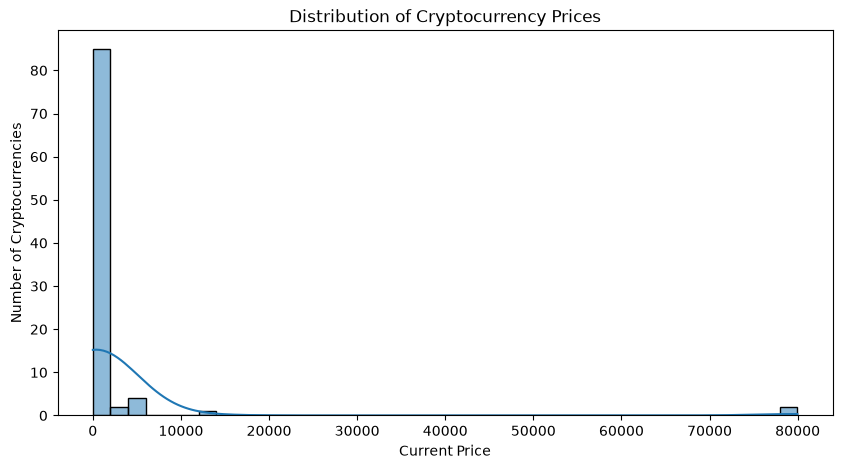

In [69]:
# Current Price Distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    crypto_df["current_price"].dropna(),
    bins=40,
    kde=True
)

plt.title("Distribution of Cryptocurrency Prices")
plt.xlabel("Current Price")
plt.ylabel("Number of Cryptocurrencies")
plt.show()

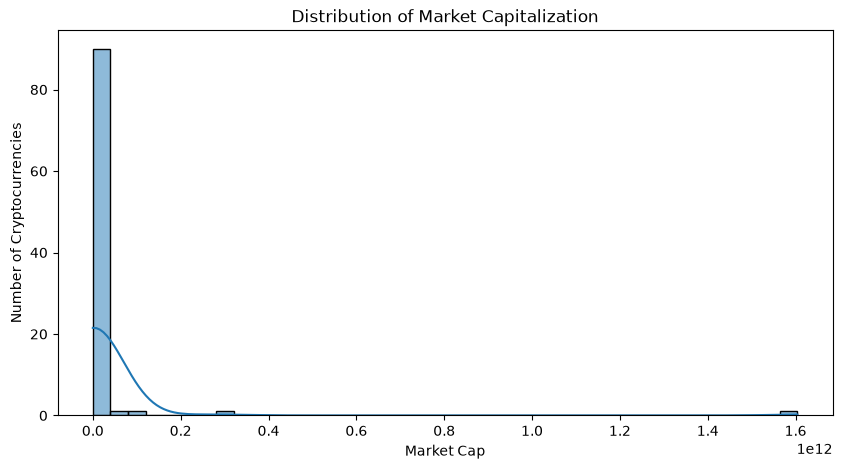

In [70]:
# Market Capitalization Distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    crypto_df["market_cap"].dropna(),
    bins=40,
    kde=True
)

plt.title("Distribution of Market Capitalization")
plt.xlabel("Market Cap")
plt.ylabel("Number of Cryptocurrencies")
plt.show()

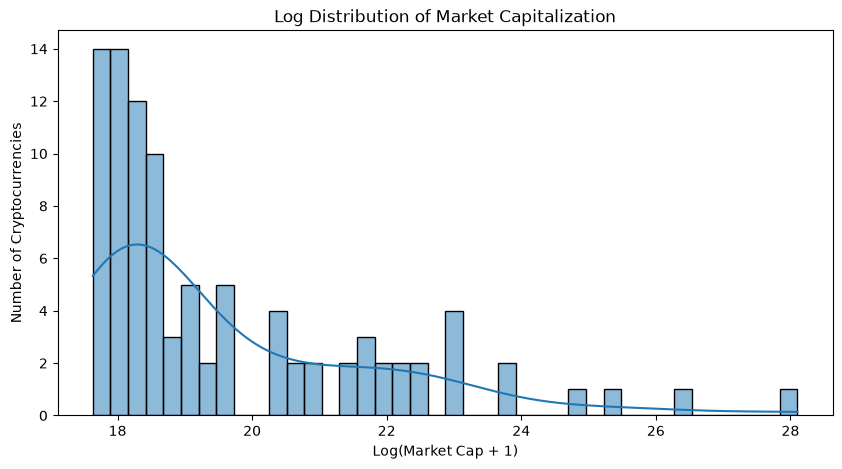

In [71]:
plt.figure(figsize=(10, 5))

sns.histplot(
    np.log1p(crypto_df["market_cap"].dropna()),
    bins=40,
    kde=True
)

plt.title("Log Distribution of Market Capitalization")
plt.xlabel("Log(Market Cap + 1)")
plt.ylabel("Number of Cryptocurrencies")
plt.show()

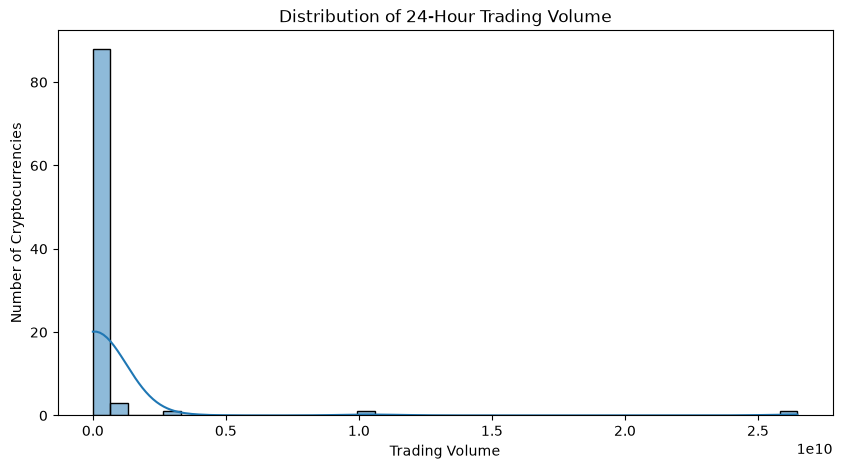

In [72]:
# Trading Volume Distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    crypto_df["total_volume"].dropna(),
    bins=40,
    kde=True
)

plt.title("Distribution of 24-Hour Trading Volume")
plt.xlabel("Trading Volume")
plt.ylabel("Number of Cryptocurrencies")
plt.show()

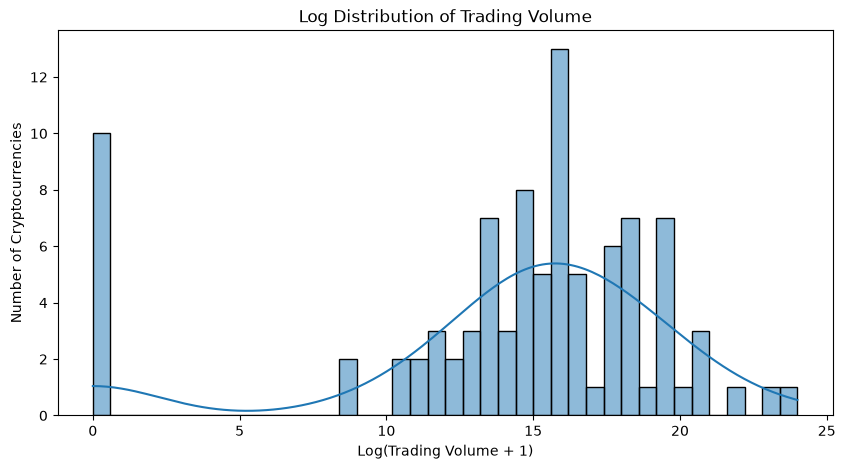

In [73]:
plt.figure(figsize=(10, 5))

sns.histplot(
    np.log1p(crypto_df["total_volume"].dropna()),
    bins=40,
    kde=True
)

plt.title("Log Distribution of Trading Volume")
plt.xlabel("Log(Trading Volume + 1)")
plt.ylabel("Number of Cryptocurrencies")
plt.show()

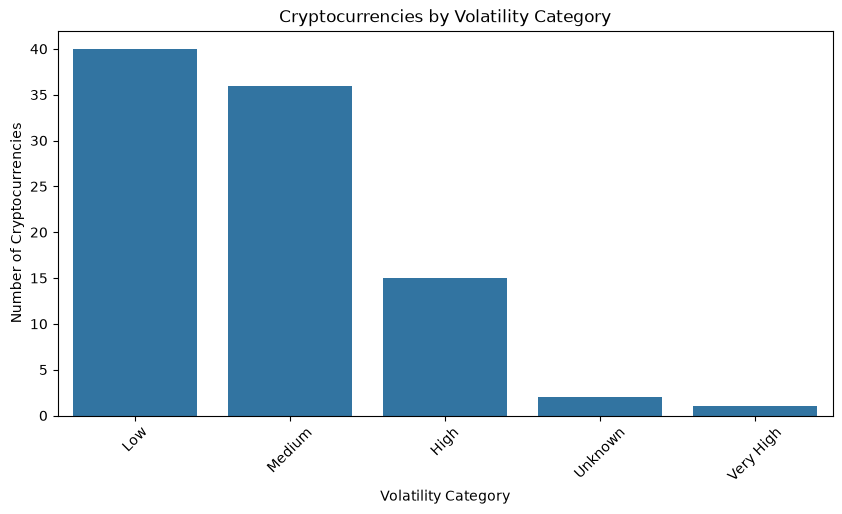

In [74]:
# Volatility Category

plt.figure(figsize=(10, 5))

sns.countplot(
    data=crypto_df,
    x="volatility_category",
    order=crypto_df["volatility_category"].value_counts().index
)

plt.title("Cryptocurrencies by Volatility Category")
plt.xlabel("Volatility Category")
plt.ylabel("Number of Cryptocurrencies")
plt.xticks(rotation=45)
plt.show()

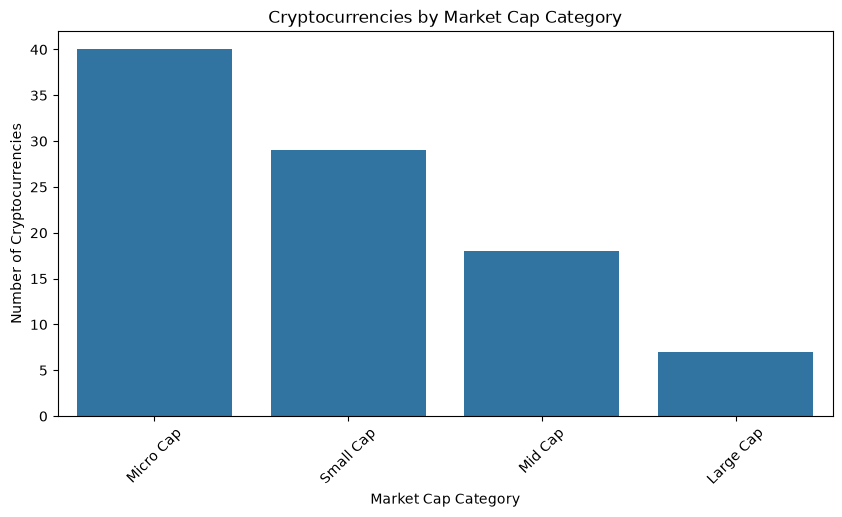

In [75]:
# Market Cap Category

plt.figure(figsize=(10, 5))

sns.countplot(
    data=crypto_df,
    x="market_cap_category",
    order=crypto_df["market_cap_category"].value_counts().index
)

plt.title("Cryptocurrencies by Market Cap Category")
plt.xlabel("Market Cap Category")
plt.ylabel("Number of Cryptocurrencies")
plt.xticks(rotation=45)
plt.show()

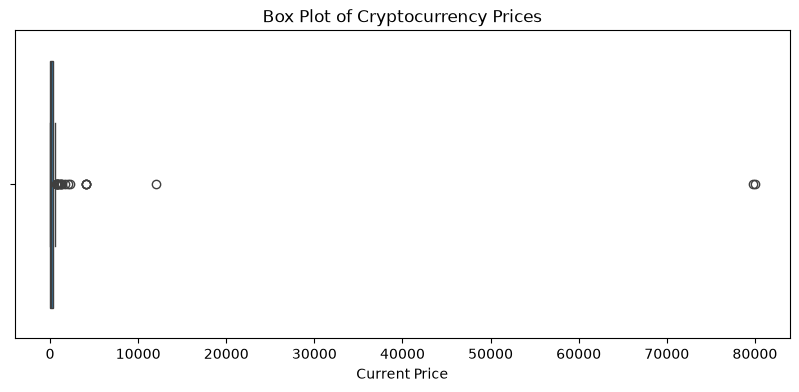

In [76]:
# Box Plots — Outlier Analysis
# Current Price

plt.figure(figsize=(10, 4))

sns.boxplot(x=crypto_df["current_price"])

plt.title("Box Plot of Cryptocurrency Prices")
plt.xlabel("Current Price")
plt.show()

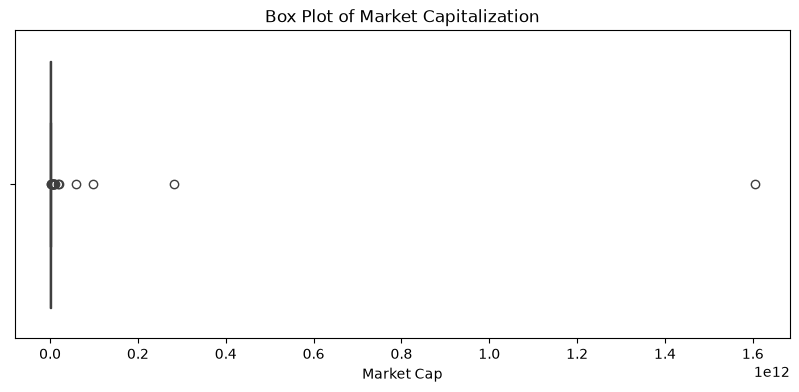

In [77]:
# Market Cap

plt.figure(figsize=(10, 4))

sns.boxplot(x=crypto_df["market_cap"])

plt.title("Box Plot of Market Capitalization")
plt.xlabel("Market Cap")
plt.show()

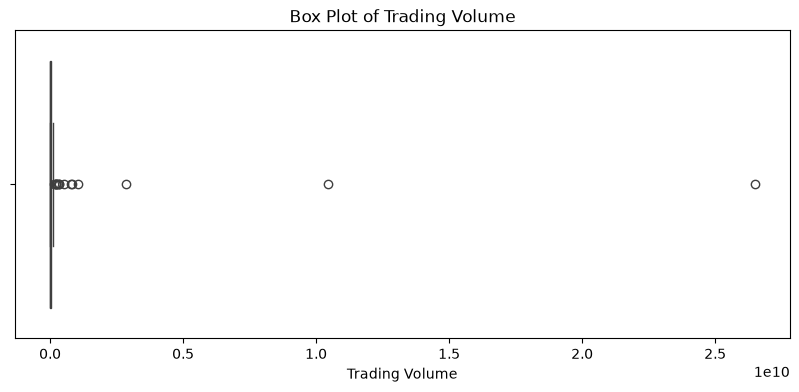

In [78]:
# Trading Volume

plt.figure(figsize=(10, 4))

sns.boxplot(x=crypto_df["total_volume"])

plt.title("Box Plot of Trading Volume")
plt.xlabel("Trading Volume")
plt.show()

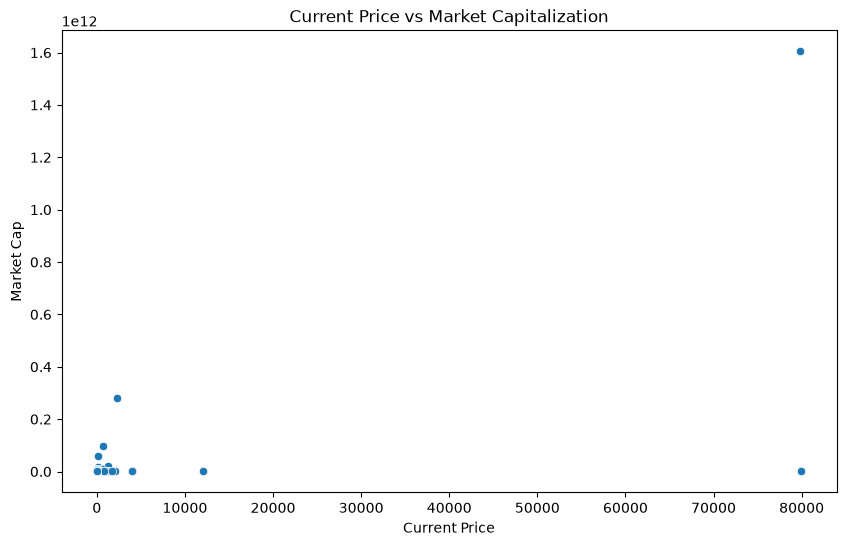

In [79]:
# Bivariate Analysis
# Price vs Market Cap

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=crypto_df,
    x="current_price",
    y="market_cap"
)

plt.title("Current Price vs Market Capitalization")
plt.xlabel("Current Price")
plt.ylabel("Market Cap")
plt.show()

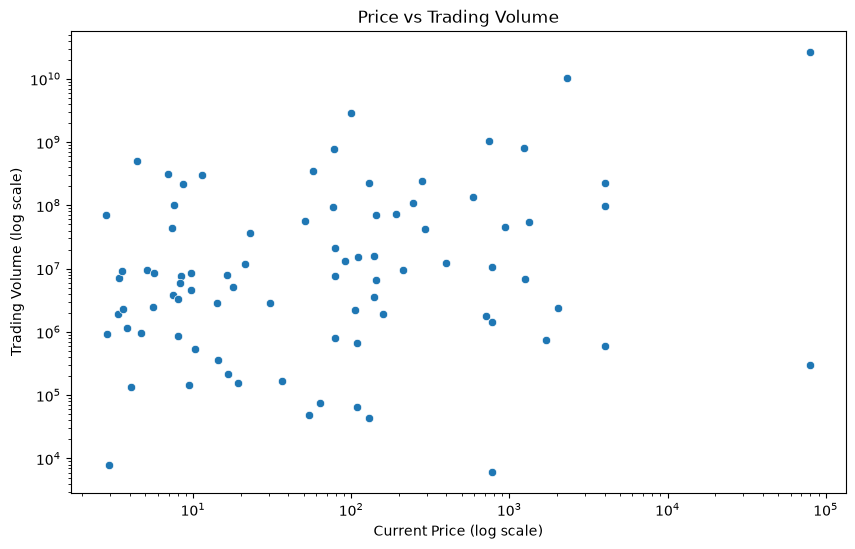

In [80]:
# Price vs Trading Volume

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=crypto_df,
    x="current_price",
    y="total_volume"
)

plt.xscale("log")
plt.yscale("log")

plt.title("Price vs Trading Volume")
plt.xlabel("Current Price (log scale)")
plt.ylabel("Trading Volume (log scale)")
plt.show()

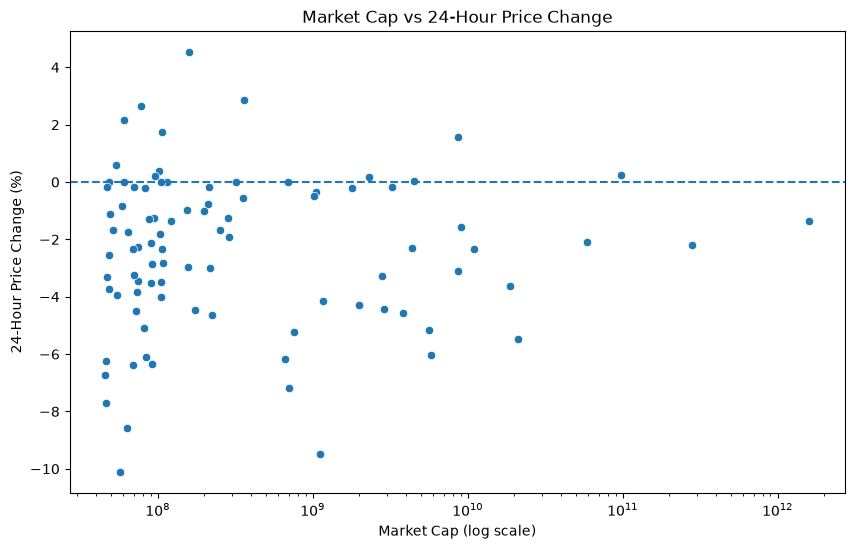

In [81]:
# Market Cap vs 24-Hour Price Change

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=crypto_df,
    x="market_cap",
    y="price_change_percentage_24h"
)

plt.xscale("log")

plt.axhline(0, linestyle="--")

plt.title("Market Cap vs 24-Hour Price Change")
plt.xlabel("Market Cap (log scale)")
plt.ylabel("24-Hour Price Change (%)")
plt.show()

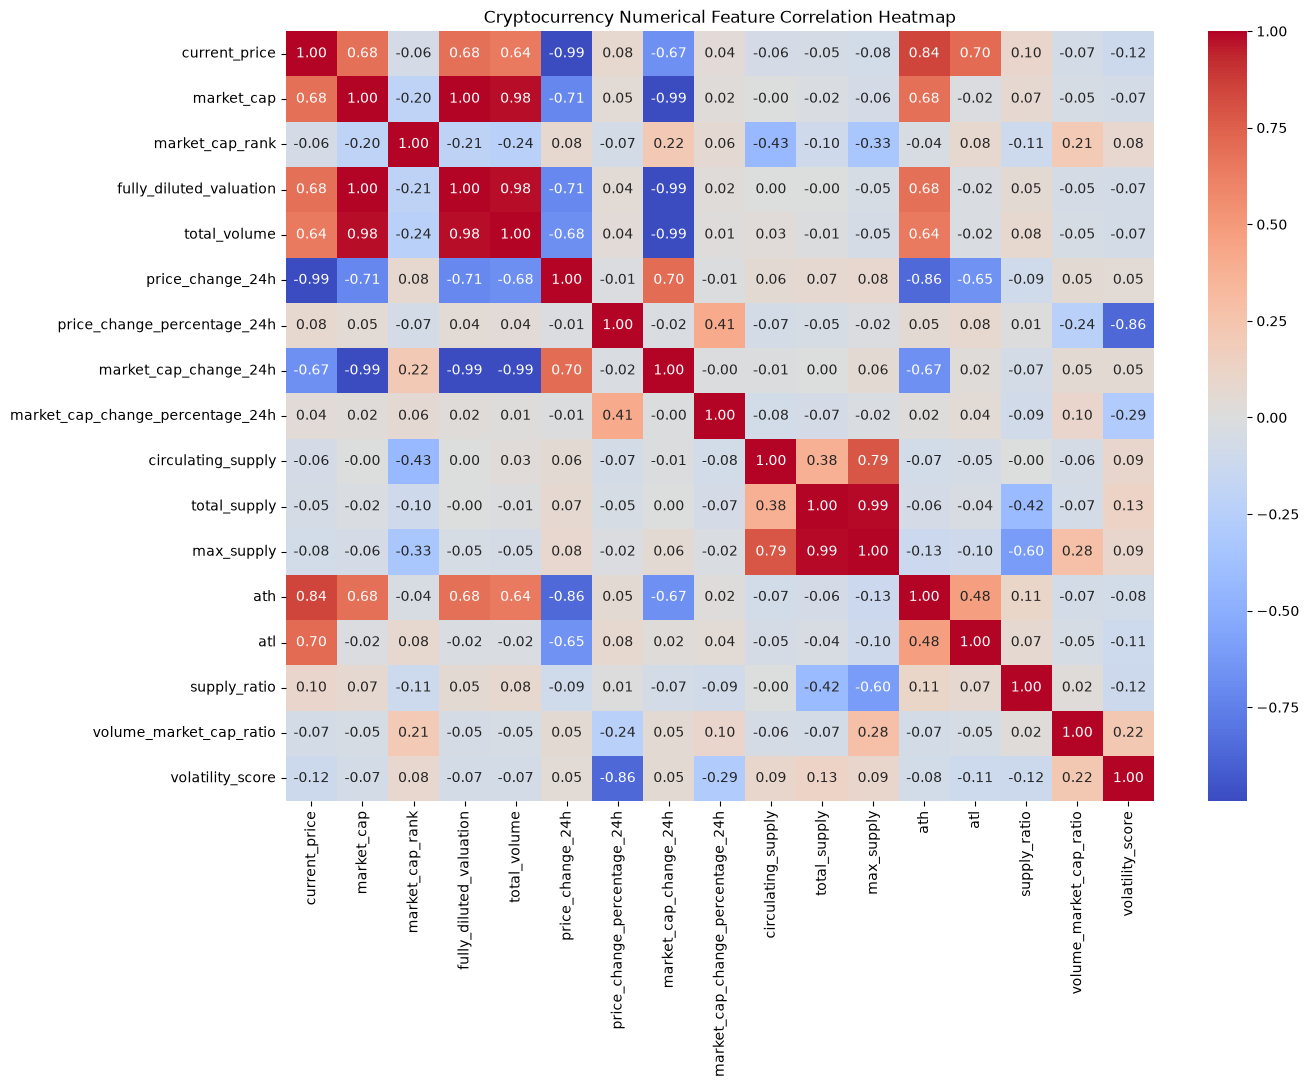

In [82]:
# Correlation Heatmap

numeric_cols = [
    "current_price",
    "market_cap",
    "market_cap_rank",
    "fully_diluted_valuation",
    "total_volume",
    "price_change_24h",
    "price_change_percentage_24h",
    "market_cap_change_24h",
    "market_cap_change_percentage_24h",
    "circulating_supply",
    "total_supply",
    "max_supply",
    "ath",
    "atl",
    "supply_ratio",
    "volume_market_cap_ratio",
    "volatility_score"
]

corr = crypto_df[numeric_cols].corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Cryptocurrency Numerical Feature Correlation Heatmap")
plt.show()

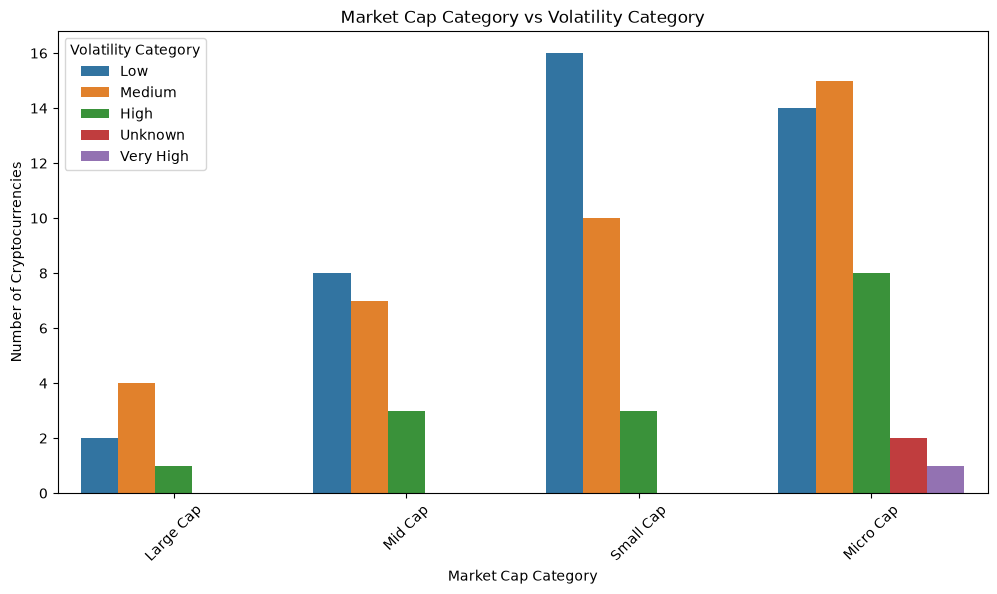

In [83]:
# Multivariate Analysis

plt.figure(figsize=(12, 6))

sns.countplot(
    data=crypto_df,
    x="market_cap_category",
    hue="volatility_category"
)

plt.title("Market Cap Category vs Volatility Category")
plt.xlabel("Market Cap Category")
plt.ylabel("Number of Cryptocurrencies")
plt.xticks(rotation=45)
plt.legend(title="Volatility Category")
plt.show()

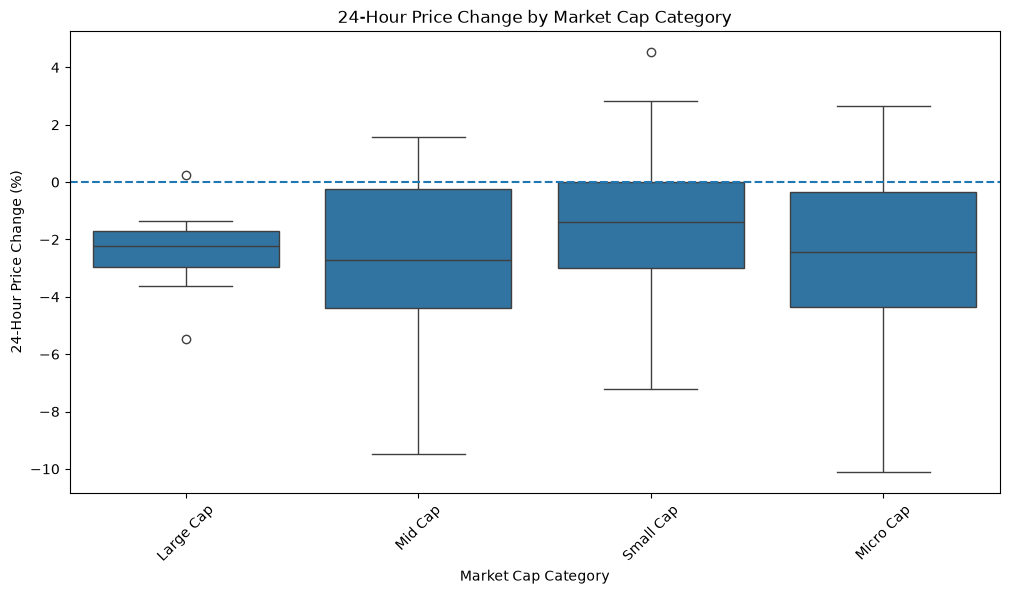

In [84]:
# Market Cap Category vs 24-Hour Price Change

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=crypto_df,
    x="market_cap_category",
    y="price_change_percentage_24h"
)

plt.axhline(0, linestyle="--")

plt.title("24-Hour Price Change by Market Cap Category")
plt.xlabel("Market Cap Category")
plt.ylabel("24-Hour Price Change (%)")
plt.xticks(rotation=45)
plt.show()

In [85]:
# Summary Statistics by Market Cap Category

market_cap_summary = (
    crypto_df
    .groupby("market_cap_category")
    .agg(
        crypto_count=("id", "count"),
        avg_price=("current_price", "mean"),
        median_price=("current_price", "median"),
        avg_market_cap=("market_cap", "mean"),
        avg_volume=("total_volume", "mean"),
        avg_price_change_24h=("price_change_percentage_24h", "mean"),
        avg_volatility=("volatility_score", "mean")
    )
    .round(2)
)

market_cap_summary

,crypto_count,avg_price,median_price,avg_market_cap,avg_volume,avg_price_change_24h,avg_volatility
market_cap_category,,,,,,,
Large Cap,7,12121.60,746.88,2.990699e+11,6.077276e+09,-2.41,2.47
Micro Cap,40,2803.28,98.84,6.750637e+07,6.874639e+06,-2.84,3.13
Mid Cap,18,513.70,40.18,3.884359e+09,1.584613e+08,-2.65,2.85
Small Cap,29,122.34,21.16,2.570497e+08,1.337252e+07,-1.67,2.32


In [86]:
# Top Cryptocurrencies

top_market_cap = (
    crypto_df
    .nlargest(10, "market_cap")
    [["name", "symbol", "market_cap", "current_price"]]
)

top_market_cap

,name,symbol,market_cap,current_price
0,Bitcoin,btc,1604131274034,79797.00
1,Ethereum,eth,281519109013,2304.65
3,BNB,bnb,98216391200,746.88
6,Solana,sol,58775153809,99.64
9,Zcash,zec,21043722092,1237.22
10,Hyperliquid,hype,18743599996,78.28
12,Monero,xmr,11059880860,587.54
14,WhiteBIT Coin,wbt,9079925289,76.51
15,LEO Token,leo,8702171716,9.46
16,Chainlink,link,8691758366,11.34


In [87]:
# Top 10 by Trading Volume

top_volume = (
    crypto_df
    .nlargest(10, "total_volume")
    [["name", "symbol", "total_volume", "market_cap"]]
)

top_volume

,name,symbol,total_volume,market_cap
0,Bitcoin,btc,2.648268e+10,1604131274034
1,Ethereum,eth,1.044390e+10,281519109013
6,Solana,sol,2.851402e+09,58775153809
3,BNB,bnb,1.030632e+09,98216391200
9,Zcash,zec,8.077907e+08,21043722092
10,Hyperliquid,hype,7.897592e+08,18743599996
19,NEAR Protocol,near,5.045419e+08,5797311664
24,Litecoin,ltc,3.453880e+08,4474940941
25,Uniswap,uni,3.170135e+08,4344895981
16,Chainlink,link,3.059694e+08,8691758366


In [88]:
# Top 10 Most Volatile

top_volatile = (
    crypto_df
    .nlargest(10, "volatility_score")
    [["name", "symbol", "volatility_score",
      "volatility_category",
      "price_change_percentage_24h"]]
)

top_volatile

,name,symbol,volatility_score,volatility_category,price_change_percentage_24h
414,Alphabet (bStocks Tokenized Stock),googlb,10.11299,Very High,-10.11299
71,Venice Token,vvv,9.48767,High,-9.48767
378,Diem,diem,8.57878,High,-8.57878
487,Score,sn44,7.70063,High,-7.70063
85,Lighter,lit,7.19824,High,-7.19824
493,affine,sn120,6.71562,High,-6.71562
364,Kusama,ksm,6.37653,High,-6.37653
293,Verified Emeralds,verem,6.32975,High,-6.32975
485,Tellor Tributes,trb,6.23913,High,-6.23913
89,Dash,dash,6.17995,High,-6.17995


In [92]:
# Interactive Visualization
# Market Cap vs Price

import plotly.express as px
fig = px.scatter(
    crypto_df,
    x="current_price",
    y="market_cap",
    hover_name="name",
    size="total_volume",
    color="market_cap_category",
    log_x=True,
    log_y=True,
    title="Cryptocurrency Price vs Market Cap"
)

fig.show()

In [91]:
%pip install plotly

   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.7 MB 2.5 MB/s eta 0:00:04
   ----- ---------------------------------- 1.3/9.7 MB 2.6 MB/s eta 0:00:04
   -------- ------------------------------- 2.1/9.7 MB 3.0 MB/s eta 0:00:03
   ---------- ----------------------------- 2.6/9.7 MB 2.9 MB/s eta 0:00:03
   ------------ --------------------------- 3.1/9.7 MB 3.0 MB/s eta 0:00:03
   --------------- ------------------------ 3.7/9.7 MB 2.8 MB/s eta 0:00:03
   ------------------ --------------------- 4.5/9.7 MB 2.9 MB/s eta 0:00:02
   --------------------- ------------------ 5.2/9.7 MB 3.0 MB/s eta 0:00:02
   ---------------------- ----------------- 5.5/9.7 MB 3.0 MB/s eta 0:00:02
   ------------------------ --------------- 6.0/9.7 MB 2.8 MB/s eta 0:00:02
   ------------------------- -------------- 6.3/9.7 MB 2.8 MB/s eta 0:00:02
   -----------------------

In [ ]:
fig = px.scatter(
    crypto_df,
    x="market_cap",
    y="price_change_percentage_24h",
    hover_name="name",
    size="total_volume",
    color="volatility_category",
    log_x=True,
    title="Market Cap vs 24-Hour Price Change"
)

fig.add_hline(y=0)

fig.show()

In [ ]:
# Overall EDA Summary
crypto_df.describe().T
print("Market Cap Categories:")
print(crypto_df["market_cap_category"].value_counts())

print("\nVolatility Categories:")
print(crypto_df["volatility_category"].value_counts())

Market Cap Categories:
market_cap_category
Micro Cap    31
Small Cap    28
Mid Cap      17
Large Cap     7
Name: count, dtype: int64

Volatility Categories:
volatility_category
Low          50
Medium       25
High          6
Very High     1
Unknown       1
Name: count, dtype: int64


# Books EDA

In [ ]:
# Basic Dataset Overview

print("Shape:", data_df.shape)

print("\nColumns:")
print(data_df.columns.tolist())

print("\nData Types:")
print(data_df.dtypes)

print("\nMissing Values:")
print(data_df.isna().sum())

print("\nDuplicate Rows:")
print(data_df.duplicated().sum())

data_df.describe(include="all").T

Shape: (0, 10)

Columns:
['title', 'price', 'rating', 'availability', 'book_url', 'stock_count', 'price_range', 'stock_status', 'price_category', 'rating_group']

Data Types:
title                  str
price              float64
rating               int64
availability           str
book_url               str
stock_count          int64
price_range       category
stock_status         int64
price_category     float64
rating_group         int64
dtype: object

Missing Values:
title             0
price             0
rating            0
availability      0
book_url          0
stock_count       0
price_range       0
stock_status      0
price_category    0
rating_group      0
dtype: int64

Duplicate Rows:
0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
title,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rating,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
availability,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
book_url,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stock_count,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price_range,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stock_status,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price_category,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rating_group,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


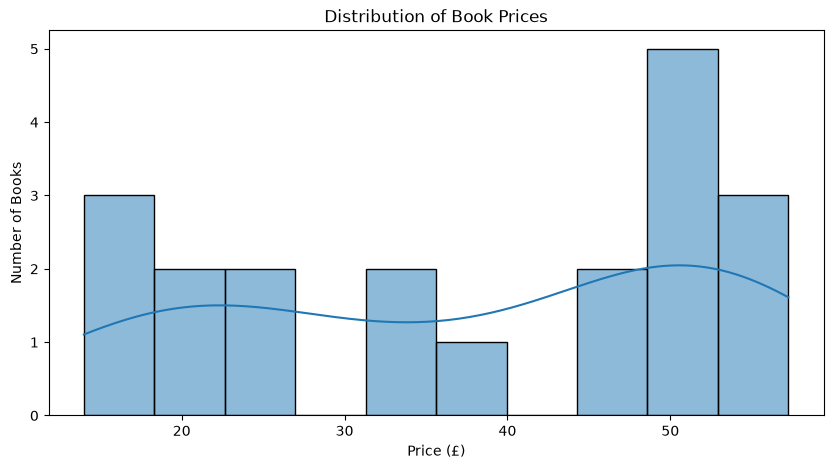

In [ ]:
# Book Price Distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=data_df,
    x="price",
    bins=10,
    kde=True
)

plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")

plt.show()

In [ ]:
data_df["price"] = (
    data_df["price"]
    .astype(str)
    .str.replace("£", "", regex=False)
    .str.strip()
    .astype(float)
)
print(data_df["price"].dtype)
print(data_df["price"].head())

float64
0    51.77
1    53.74
2    50.10
3    47.82
4    54.23
Name: price, dtype: float64


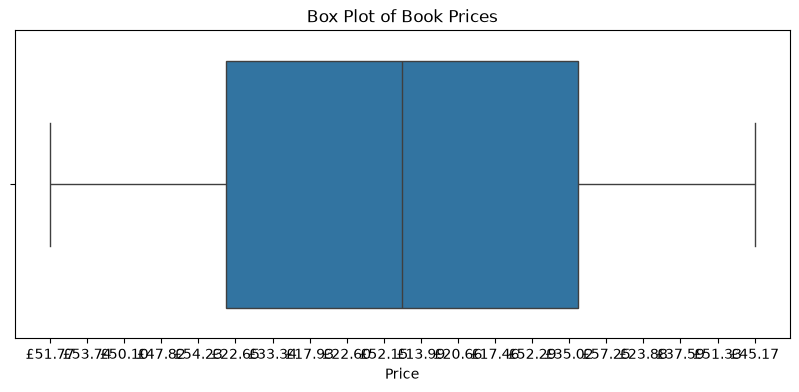

In [ ]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=data_df["price"])

plt.title("Box Plot of Book Prices")
plt.xlabel("Price")
plt.show()

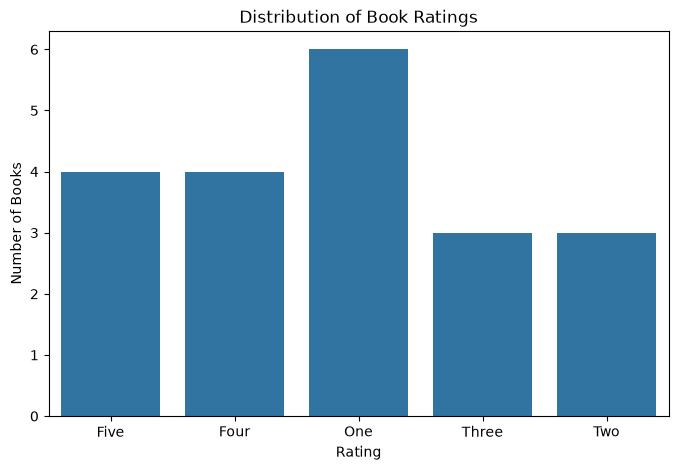

In [ ]:
# Rating Distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=data_df,
    x="rating",
    order=sorted(data_df["rating"].dropna().unique())
)

plt.title("Distribution of Book Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Books")
plt.show()

In [ ]:
print("Shape:", data_df.shape)
print("Rows:", len(data_df))
print(data_df.head())

Shape: (0, 10)
Rows: 0
Empty DataFrame
Columns: [title, price, rating, availability, book_url, stock_count, price_range, stock_status, price_category, rating_group]
Index: []


In [ ]:
%whos

Variable              Type             Data/Info
------------------------------------------------
API_KEY               str              CG-ZcTSmjFqi7Yg9XdsXYBLZPiX
BeautifulSoup         type             <class 'bs4.BeautifulSoup'>
all_crypto            list             n=500
availability          str              In stock
book                  Tag              <article class="product_p<...>form>\n</div>\n</article>
book_url              str              catalogue/its-only-the-himalayas_981/index.html
col                   str              max_supply
corr                  DataFrame        Shape: (17, 17)
crypto_check          DataFrame        Shape: (500, 26)
crypto_df             DataFrame        Shape: (83, 34)
data                  list             n=20
data_df               DataFrame        Shape: (0, 10)
detect_iqr_outliers   function         <function detect_iqr_outl<...>rs at 0x000002205F52B9C0>
features              list             n=3
headers               dict             n=

In [ ]:
print(len(data))
print(data[:2])

data_df = pd.DataFrame(data)
print(data_df.shape)

20
[{'title': 'A Light in the Attic', 'price': '£51.77', 'rating': 'Three', 'availability': 'In stock', 'book_url': 'catalogue/a-light-in-the-attic_1000/index.html'}, {'title': 'Tipping the Velvet', 'price': '£53.74', 'rating': 'One', 'availability': 'In stock', 'book_url': 'catalogue/tipping-the-velvet_999/index.html'}]
(20, 5)
